# MRNet ThreeView Mean Pooling



## 1 · Install / imports

In [ ]:
!pip -q install scikit-learn pandas matplotlib tqdm

In [ ]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    accuracy_score, precision_score, recall_score, f1_score
)
from google.colab import drive

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


## 2 · Configuration and Drive

In [ ]:
EPOCHS = 3
LEARNING_RATE = 1e-3
LABEL_COLUMNS = ["abnormal", "acl", "meniscus"]
VIEWS = ["sagittal", "coronal", "axial"]

drive.mount("/content/drive")
DRIVE_ROOT = Path("/content/drive/MyDrive/mrnet")
CACHE_ROOT = DRIVE_ROOT / "cache"
RESULTS_DIR = DRIVE_ROOT / "results" / "exp3_threeview_mean"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Cache root:", CACHE_ROOT)
print("Results will be saved to:", RESULTS_DIR)

Mounted at /content/drive
Cache root: /content/drive/MyDrive/mrnet/cache
Results will be saved to: /content/drive/MyDrive/mrnet/results/exp3_threeview_mean


## 3 · Load  exam tables

In [ ]:
train_exams = pd.read_parquet(DRIVE_ROOT / "train_exams.parquet")
valid_exams = pd.read_parquet(DRIVE_ROOT / "valid_exams.parquet")

# Normalize IDs consistently for file lookup.
for df in (train_exams, valid_exams):
    df["exam_id"] = (
        df["exam_id"].astype(str).str.replace(r"\.0$", "", regex=True).str.zfill(4)
    )
    for label in LABEL_COLUMNS:
        df[label] = pd.to_numeric(df[label], errors="coerce")
    df.dropna(subset=LABEL_COLUMNS, inplace=True)
    df.reset_index(drop=True, inplace=True)

print(f"Train exams: {len(train_exams)} | Validation exams: {len(valid_exams)}")
print("\nPositive-label rates:")
display(pd.DataFrame({
    "train": train_exams[LABEL_COLUMNS].mean(),
    "validation": valid_exams[LABEL_COLUMNS].mean()
}).round(3))

overlap = set(train_exams["exam_id"]) & set(valid_exams["exam_id"])
print("Train/validation ID overlap:", len(overlap))
if overlap:
    print("WARNING — overlapping IDs:", sorted(overlap)[:10])

# Check that every selected exam has all three cached volumes.
def missing_view_files(exams, split):
    missing = []
    for exam_id in exams["exam_id"]:
        for view in VIEWS:
            path = CACHE_ROOT / split / view / f"{exam_id}.npy"
            if not path.exists():
                missing.append((exam_id, view, str(path)))
    return missing

train_missing = missing_view_files(train_exams, "train")
valid_missing = missing_view_files(valid_exams, "valid")
print("Missing train view files:", len(train_missing))
print("Missing validation view files:", len(valid_missing))
if train_missing[:5]:
    print("Examples:", train_missing[:5])
if valid_missing[:5]:
    print("Examples:", valid_missing[:5])

if train_missing or valid_missing:
    raise FileNotFoundError(
        "Some cached MRI volumes are missing. Ensure sagittal, coronal, and axial "
        "volumes exist under cache/train/<view>/ and cache/valid/<view>/."
    )

Train exams: 1129 | Validation exams: 119

Positive-label rates:


,train,validation
abnormal,0.808,0.798
acl,0.184,0.454
meniscus,0.352,0.437


Train/validation ID overlap: 0
Missing train view files: 0
Missing validation view files: 0


## 4 · Three-view dataset

In [ ]:
class ThreeViewDataset(Dataset):
    """Returns three MRI volumes, labels, and exam ID for one exam."""
    def __init__(self, exams, cache_root, split):
        self.exams = exams.reset_index(drop=True)
        self.cache_root = Path(cache_root)
        self.split = split

    def __len__(self):
        return len(self.exams)

    def __getitem__(self, idx):
        row = self.exams.iloc[idx]
        exam_id = row["exam_id"]
        volumes = []
        for view in VIEWS:
            arr = np.load(self.cache_root / self.split / view / f"{exam_id}.npy")
            volumes.append(torch.from_numpy(arr.astype(np.float32) / 255.0))
        labels = torch.tensor(row[LABEL_COLUMNS].to_numpy(dtype=np.float32))
        return volumes[0], volumes[1], volumes[2], labels, exam_id

train_ds = ThreeViewDataset(train_exams, CACHE_ROOT, "train")
valid_ds = ThreeViewDataset(valid_exams, CACHE_ROOT, "valid")

train_loader = DataLoader(
    train_ds, batch_size=1, shuffle=True, num_workers=0,
    pin_memory=(device.type == "cuda")
)
valid_loader = DataLoader(
    valid_ds, batch_size=1, shuffle=False, num_workers=0,
    pin_memory=(device.type == "cuda")
)

sample = train_ds[0]
print("Example exam:", sample[-1])
print("View shapes:", [tuple(v.shape) for v in sample[:3]])
print("Labels:", sample[3].tolist())

Example exam: 0060
View shapes: [(18, 256, 256), (28, 256, 256), (39, 256, 256)]
Labels: [0.0, 0.0, 0.0]


## 5 · Model: ResNet18 + mean pooling per view

In [ ]:
def prepare_slices(volume: torch.Tensor, size: int = 224) -> torch.Tensor:
    # (S,H,W) -> (S,3,size,size), repeating grayscale into RGB channels.
    x = volume.unsqueeze(1)
    x = F.interpolate(x, size=(size, size), mode="bilinear", align_corners=False)
    return x.repeat(1, 3, 1, 1)


class ThreeViewMeanPoolModel(nn.Module):
    """
    Shared frozen ResNet18 encodes slices from each view.
    Slice features are mean-pooled within each view.
    The three 512-d view vectors are concatenated and classified.
    """
    def __init__(self):
        super().__init__()
        from torchvision.models import resnet18, ResNet18_Weights
        backbone = resnet18(weights=ResNet18_Weights.DEFAULT)
        self.encoder = nn.Sequential(*list(backbone.children())[:-1])
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1,3,1,1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1,3,1,1))
        for p in self.encoder.parameters():
            p.requires_grad = False
        self.encoder.eval()
        self.classifier = nn.Linear(512 * len(VIEWS), len(LABEL_COLUMNS))

    def train(self, mode=True):
        super().train(mode)
        self.encoder.eval()
        return self

    @torch.no_grad()
    def encode_volume(self, volume):
        slices = prepare_slices(volume)
        slices = (slices - self.mean) / self.std
        features = []
        for start in range(0, slices.shape[0], 8):
            features.append(self.encoder(slices[start:start+8]).flatten(1))
        slice_features = torch.cat(features, dim=0)  # (S,512)
        return slice_features.mean(dim=0)             # (512,)

    def forward(self, sagittal, coronal, axial):
        view_features = [
            self.encode_volume(sagittal),
            self.encode_volume(coronal),
            self.encode_volume(axial),
        ]
        combined = torch.cat(view_features, dim=0)    # (1536,)
        logits = self.classifier(combined)            # (3,)
        return logits

model = ThreeViewMeanPoolModel().to(device)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {trainable:,}")
print("Encoder frozen:", not any(p.requires_grad for p in model.encoder.parameters()))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 197MB/s]


Trainable parameters: 4,611
Encoder frozen: True


## 6 · Train for 3 epochs

In [ ]:
y_train = train_exams[LABEL_COLUMNS].to_numpy(dtype=np.float32)
pos = y_train.sum(axis=0)
neg = len(y_train) - pos
pos_weight = torch.tensor(
    neg / np.maximum(pos, 1.0), dtype=torch.float32, device=device
)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE
)

history = []
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    for sag, cor, axi, target, _exam_id in tqdm(
        train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS}"
    ):
        sag = sag.squeeze(0).to(device)
        cor = cor.squeeze(0).to(device)
        axi = axi.squeeze(0).to(device)
        target = target.squeeze(0).to(device)

        optimizer.zero_grad()
        logits = model(sag, cor, axi)
        loss = criterion(logits, target)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    mean_loss = total_loss / max(len(train_loader), 1)
    history.append(mean_loss)
    print(f"Epoch {epoch + 1}/{EPOCHS} — training loss: {mean_loss:.4f}")

print("Training complete.")

Epoch 1/3:   0%|          | 0/1129 [00:00<?, ?it/s]

Epoch 1/3 — training loss: 0.8560


Epoch 2/3:   0%|          | 0/1129 [00:00<?, ?it/s]

Epoch 2/3 — training loss: 0.7855


Epoch 3/3:   0%|          | 0/1129 [00:00<?, ?it/s]

Epoch 3/3 — training loss: 0.7600
Training complete.


## 7 · Evaluate on the fixed validation split

In [ ]:
model.eval()
all_targets, all_probs, all_ids = [], [], []

with torch.no_grad():
    for sag, cor, axi, target, exam_id in tqdm(valid_loader, desc="Validation"):
        sag = sag.squeeze(0).to(device)
        cor = cor.squeeze(0).to(device)
        axi = axi.squeeze(0).to(device)
        logits = model(sag, cor, axi)
        probs = torch.sigmoid(logits).cpu().numpy()

        all_targets.append(target.squeeze(0).numpy())
        all_probs.append(probs)
        all_ids.append(exam_id[0])

y_true = np.asarray(all_targets)
y_prob = np.asarray(all_probs)
y_pred = (y_prob >= 0.5).astype(int)

rows = []
for j, label in enumerate(LABEL_COLUMNS):
    auc = roc_auc_score(y_true[:, j], y_prob[:, j]) if len(np.unique(y_true[:, j])) == 2 else float("nan")
    ap = average_precision_score(y_true[:, j], y_prob[:, j]) if y_true[:, j].sum() > 0 else float("nan")
    rows.append({
        "label": label,
        "ROC_AUC": round(auc, 3),
        "Avg_Precision": round(ap, 3),
        "Accuracy@0.5": round(accuracy_score(y_true[:, j], y_pred[:, j]), 3),
        "Precision@0.5": round(precision_score(y_true[:, j], y_pred[:, j], zero_division=0), 3),
        "Recall@0.5": round(recall_score(y_true[:, j], y_pred[:, j], zero_division=0), 3),
        "F1@0.5": round(f1_score(y_true[:, j], y_pred[:, j], zero_division=0), 3),
    })

metrics_df = pd.DataFrame(rows)
metrics_df.insert(0, "experiment", 3)
metrics_df.insert(1, "encoder", "resnet18")
display(metrics_df)

Validation:   0%|          | 0/119 [00:00<?, ?it/s]

,experiment,encoder,label,ROC_AUC,Avg_Precision,Accuracy@0.5,Precision@0.5,Recall@0.5,F1@0.5
0,3,resnet18,abnormal,0.911,0.974,0.899,0.928,0.947,0.938
1,3,resnet18,acl,0.879,0.859,0.756,0.838,0.574,0.681
2,3,resnet18,meniscus,0.757,0.713,0.697,0.690,0.558,0.617


## 8 · Plot training loss

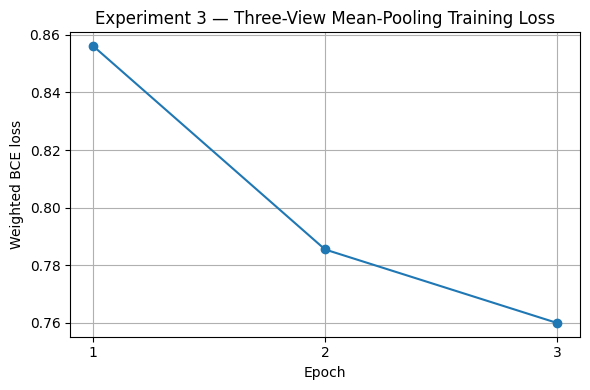

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(history) + 1), history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Weighted BCE loss")
plt.title("Experiment 3 — Three-View Mean-Pooling Training Loss")
plt.xticks(range(1, len(history) + 1))
plt.grid(True)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "loss_curve.png", dpi=120)
plt.show()

## 9 · Save checkpoint and metrics

In [ ]:
torch.save({
    "model_state_dict": model.state_dict(),
    "label_columns": LABEL_COLUMNS,
    "views": VIEWS,
    "experiment": 3,
    "encoder": "resnet18",
    "pooling": "mean_per_view_then_concatenate",
    "epochs": EPOCHS,
    "train_history": history,
    "seed": SEED,
}, RESULTS_DIR / "checkpoint.pt")

metrics_df.to_csv(RESULTS_DIR / "metrics.csv", index=False)

shared_csv = DRIVE_ROOT / "results" / "all_results.csv"
if shared_csv.exists():
    existing = pd.read_csv(shared_csv)
    existing = existing[existing["experiment"] != 3]
    combined = pd.concat([existing, metrics_df], ignore_index=True)
else:
    combined = metrics_df
combined.to_csv(shared_csv, index=False)

print("Checkpoint:", RESULTS_DIR / "checkpoint.pt")
print("Metrics:", RESULTS_DIR / "metrics.csv")
print("Shared results:", shared_csv)

Checkpoint: /content/drive/MyDrive/mrnet/results/exp3_threeview_mean/checkpoint.pt
Metrics: /content/drive/MyDrive/mrnet/results/exp3_threeview_mean/metrics.csv
Shared results: /content/drive/MyDrive/mrnet/results/all_results.csv


## 10 · Interpretation notes

- Compare this run with Experiment 1 (sagittal-only mean pooling) to estimate the value of adding the coronal and axial views.
- Compare this run with a future three-view attention model to estimate the value of attention when all views are available.
- Keep the validation exam IDs fixed across experiments.
- ROC-AUC and average precision are ranking metrics; precision/recall/F1 here use a fixed threshold of 0.5.
- These are exploratory results on a small validation set, not evidence of clinical readiness.